# 06 — Dependência de provedores domésticos vs. estrangeiros

**Pergunta:** as empresas usam provedores de DNS do próprio país, de outros países, ou uma
mistura dos dois? Para onde vai essa dependência? Como isso muda entre os blocos (EUA, UE,
BRICS, Outros)?

**Escopo:** apenas IPv4. O país do provedor é o país do **grupo controlador** do ASN
(`dp_as_country_code`), e não onde ficam os servidores.

**Duas ponderações, sempre lado a lado:** cada gráfico é gerado duas vezes na mesma célula,
uma por **empresas** (cada empresa vale 1) e outra por **receita** (cada empresa vale a sua `revenue_ttm`).

**Definições (por empresa):**
- **domestic only:** todos os provedores da empresa são do mesmo país da sede.
- **foreign only:** nenhum provedor é do país da sede.
- **mixed:** usa provedores do país da sede *e* de outros países.

"Doméstico" é comparado em nível de **país**: uma empresa alemã usando um provedor francês
conta como estrangeiro, mesmo os dois estando na UE.

## 1. Configuração e carga dos dados

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------------------------------------------------------
# CONFIGURAÇÕES
# -----------------------------------------------------------------------------

# Como contar uma empresa que usa mais de um provedor de DNS.
# Exemplo: empresa com 4 NS, sendo 3 na Cloudflare e 1 na AWS.
#   "fracionado" -> a empresa vale 1, dividido pelo nº de NS  (Cloudflare 0,75 | AWS 0,25)
#   "principal"  -> a empresa vale 1, inteiro para o provedor com mais NS  (Cloudflare 1)
#   "uso"        -> a empresa conta 1 para cada provedor que usa  (Cloudflare 1 | AWS 1)
METODO = "fracionado"

# Todo gráfico sai em DUAS versões, geradas na mesma célula (um gráfico para cada):
#   "empresas" -> cada empresa pesa 1: participação de mercado (market share)
#   "receita"  -> cada empresa pesa a sua receita (revenue_ttm), ou seja, "quanto da economia"
# o valor do dicionário é o texto usado nos eixos dos gráficos
PONDERACOES = {"empresas": "companies", "receita": "revenue"}

# pastas de saída (tabelas em CSV e figuras em PNG)
PASTA_TAB = Path("../data/analysis")
PASTA_FIG = Path("../outputs/figures")
PASTA_TAB.mkdir(parents=True, exist_ok=True)
PASTA_FIG.mkdir(parents=True, exist_ok=True)

print("Método:", METODO, "| ponderações:", ", ".join(PONDERACOES))

Método: fracionado | ponderações: empresas, receita


In [24]:
# -----------------------------------------------------------------------------
# PAÍSES E BLOCOS
# -----------------------------------------------------------------------------
# O CompaniesMarketCap informa o país da empresa por extenso ("Brazil"), enquanto o
# país do provedor vem em código ISO de 2 letras ("BR"). Para conseguir comparar os
# dois, converto o país da empresa para o código ISO.
PAIS_ISO2 = {
    "Argentina": "AR", "Australia": "AU", "Austria": "AT", "Bahamas": "BS", "Bahrain": "BH",
    "Belgium": "BE", "Bermuda": "BM", "Brazil": "BR", "British Virgin Islands": "VG",
    "Bulgaria": "BG", "Canada": "CA", "Cayman Islands": "KY", "Chile": "CL", "China": "CN",
    "Colombia": "CO", "Costa Rica": "CR", "Cyprus": "CY", "Czech Republic": "CZ",
    "Denmark": "DK", "Egypt": "EG", "Estonia": "EE", "Finland": "FI", "France": "FR",
    "Germany": "DE", "Gibraltar": "GI", "Greece": "GR", "Guernsey": "GG", "Hong Kong": "HK",
    "Hungary": "HU", "Iceland": "IS", "India": "IN", "Indonesia": "ID", "Ireland": "IE",
    "Isle of Man": "IM", "Israel": "IL", "Italy": "IT", "Japan": "JP", "Jersey": "JE",
    "Jordan": "JO", "Kazakhstan": "KZ", "Kuwait": "KW", "Latvia": "LV",
    "Liechtenstein": "LI", "Lithuania": "LT", "Luxembourg": "LU", "Macau": "MO",
    "Malaysia": "MY", "Malta": "MT", "Mexico": "MX", "Monaco": "MC", "Netherlands": "NL",
    "New Zealand": "NZ", "Norway": "NO", "Panama": "PA", "Peru": "PE", "Philippines": "PH",
    "Poland": "PL", "Portugal": "PT", "Qatar": "QA", "Romania": "RO", "Saudi Arabia": "SA",
    "Singapore": "SG", "South Africa": "ZA", "South Korea": "KR", "Spain": "ES",
    "Sweden": "SE", "Switzerland": "CH", "Taiwan": "TW", "Thailand": "TH", "Turkey": "TR",
    "United Arab Emirates": "AE", "United Kingdom": "GB", "United States": "US",
    "Uruguay": "UY", "Vietnam": "VN", "Russia": "RU", "Ethiopia": "ET", "Iran": "IR",
}

# União Europeia (27 países)
UE27 = {"AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "GR", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"}

# BRICS: os 5 membros originais + os membros plenos que entraram em 2024/2025
# (deixei a Arábia Saudita de fora, porque a adesão formal dela é ambígua; parceiros não entram)
BRICS = {"BR", "RU", "IN", "CN", "ZA", "EG", "ET", "IR", "AE", "ID"}


def bloco_de(pais):
    """Recebe um código ISO de país e devolve o bloco: US, EU, BRICS ou Others."""
    if pais == "US":
        return "US"
    # alguns registros WHOIS trazem "EU" como país (registro regional europeu)
    if pais in UE27 or pais == "EU":
        return "EU"
    if pais in BRICS:
        return "BRICS"
    return "Others"


# ordem em que os blocos aparecem nas tabelas e gráficos ("Total" = todas as empresas)
ORDEM_BLOCOS = ["US", "EU", "BRICS", "Others", "Total"]
# PALETA PADRÃO DO TRABALHO: "tab10" do matplotlib. Todas as cores dos gráficos saem daqui.
#   0 azul | 1 laranja | 2 verde | 3 vermelho | 4 roxo | 5 marrom | 6 rosa | 7 cinza | 8 oliva | 9 ciano
PALETA = plt.get_cmap("tab10").colors

CORES_BLOCOS = {"US": PALETA[0], "EU": PALETA[1], "BRICS": PALETA[2],
                "Others": PALETA[7], "Total": PALETA[4]}

In [25]:
# -----------------------------------------------------------------------------
# ESTILO DOS GRÁFICOS E FUNÇÕES PARA SALVAR
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,      # tiro as bordas de cima e da direita
    "axes.spines.right": False,
    "axes.grid": True,             # grade horizontal leve, ajuda a ler os valores
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "legend.frameon": False,
})


def salvar_tabela(tabela, nome, pond):
    """Salva a tabela em CSV, com o método e a ponderação no nome (ex.: _fracionado_receita)."""
    tabela.to_csv(PASTA_TAB / f"{nome}_{METODO}_{pond}.csv")


def salvar_figura(fig, nome, pond):
    """Salva a figura em PNG, com o método e a ponderação no nome (ex.: _fracionado_receita)."""
    fig.savefig(PASTA_FIG / f"{nome}_{METODO}_{pond}.png", dpi=200, bbox_inches="tight")


def rotulos_com_n(n_por_bloco):
    """Cria os rótulos do eixo X no formato 'US\n(n=3,257)'."""
    return [f"{b}\n(n={n:,})" for b, n in n_por_bloco.items()]

In [26]:
# lê o dataset final (uma linha por empresa x NS x IP)
df = pd.read_parquet("../data/final/final_data.parquet")

# fico apenas com os endereços IPv4 (registros do tipo "A")
df = df[df["ip_type"] == "A"].copy()

# país e bloco da EMPRESA (onde fica a sede)
df["pais_empresa"] = df["company_country"].map(PAIS_ISO2)
df["bloco_empresa"] = df["pais_empresa"].apply(bloco_de)

# PROVEDOR = grupo econômico dono do ASN (já com o de-para aplicado)
df["provedor"] = df["dp_as_org"]
df["pais_provedor"] = df["dp_as_country_code"]
df["bloco_provedor"] = df["pais_provedor"].apply(bloco_de)

# conferência: nenhum país pode ter ficado sem código ISO
assert df["pais_empresa"].notna().all(), "há países sem código ISO no dicionário"

print(f"{len(df):,} linhas IPv4 | {df['rank'].nunique():,} empresas | {df['provedor'].nunique():,} provedores")

44,069 linhas IPv4 | 10,283 empresas | 1,112 provedores


## 2. Tabela base: uma linha por empresa × provedor

Aqui eu resumo o dataset em uma tabela com **uma linha para cada par (empresa, provedor)**,
contando quantos NS a empresa tem em cada provedor. Depois aplico o `METODO` escolhido para
definir o **peso** de cada linha:

| Método | O que significa o peso | A soma dos pesos de uma empresa |
|---|---|---|
| `fracionado` | nº de NS no provedor ÷ nº total de NS da empresa | 1 |
| `principal` | 1 só para o provedor com mais NS (os outros saem) | 1 |
| `uso` | 1 para cada provedor que a empresa usa | nº de provedores da empresa |

Por fim, multiplico o peso pelo peso da empresa nas duas ponderações, o que gera as colunas
**`valor_empresas`** (peso × 1, participação de mercado) e **`valor_receita`** (peso × receita),
que são as que todas as análises somam. Cada gráfico é gerado uma vez para cada ponderação.

In [27]:
# 1) uma linha por (empresa, provedor), contando quantos NS a empresa tem naquele provedor
ep = (df.groupby(["rank", "provedor"], as_index=False)
        .agg(company_name=("company_name", "first"),
             revenue_ttm=("revenue_ttm", "first"),
             pais_empresa=("pais_empresa", "first"),
             bloco_empresa=("bloco_empresa", "first"),
             pais_provedor=("pais_provedor", "first"),
             bloco_provedor=("bloco_provedor", "first"),
             n_ns=("ns", "nunique")))

# 2) peso de cada linha, conforme o método escolhido lá em cima
if METODO == "fracionado":
    # nº de NS no provedor dividido pelo total de NS da empresa
    ep["peso"] = ep["n_ns"] / ep.groupby("rank")["n_ns"].transform("sum")

elif METODO == "principal":
    # ordeno por empresa e, dentro dela, do provedor com mais NS para o com menos;
    # depois fico só com a primeira linha de cada empresa (em caso de empate, vale a ordem alfabética)
    ep = (ep.sort_values(["rank", "n_ns", "provedor"], ascending=[True, False, True])
            .drop_duplicates("rank"))
    ep["peso"] = 1.0

elif METODO == "uso":
    ep["peso"] = 1.0

# 3) peso da empresa nas duas ponderações (1 ou a receita) e o valor que as análises somam
ep["peso_empresas"] = 1
ep["peso_receita"] = ep["revenue_ttm"]
for pond in PONDERACOES:
    ep[f"valor_{pond}"] = ep["peso"] * ep[f"peso_{pond}"]

# 4) para ter a coluna "Total" nas comparações, duplico a tabela trocando o bloco por "Total".
#    Assim, todo groupby por bloco já devolve US, EU, BRICS, Others e Total de uma vez.
base = pd.concat([ep, ep.assign(bloco_empresa="Total")], ignore_index=True)

# nº de empresas de cada bloco (usado nos rótulos dos gráficos)
n_empresas = base.groupby("bloco_empresa")["rank"].nunique().reindex(ORDEM_BLOCOS)
display(n_empresas.to_frame("n_companies"))

# exemplo: algumas empresas que usam mais de um provedor
varios = ep[ep.groupby("rank")["provedor"].transform("count") > 1]
display(varios[["rank", "company_name", "provedor", "n_ns", "peso", "valor_empresas", "valor_receita"]].head(8))

,n_companies
bloco_empresa,
US,3257
EU,1782
BRICS,1281
Others,3963
Total,10283


,rank,company_name,provedor,n_ns,peso,valor_empresas,valor_receita
1,2,Walmart,Akamai,6,0.500,0.500,3.679200e+11
2,2,Walmart,DigiCert,6,0.500,0.500,3.679200e+11
4,4,Apple,Apple Inc.,2,0.500,0.500,2.334115e+11
5,4,Apple,"WoodyNet, Inc.",2,0.500,0.500,2.334115e+11
8,7,Sinopec,China Mobile,1,0.125,0.125,5.559370e+10
9,7,Sinopec,China Networks Inter-Exchange,2,0.250,0.250,1.111874e+11
10,7,Sinopec,China Telecom,1,0.125,0.125,5.559370e+10
11,7,Sinopec,China Unicom,4,0.500,0.500,2.223748e+11


## 3. Tipo de dependência: doméstico, estrangeiro ou misto

Para cada empresa verifico se ela tem pelo menos um provedor do próprio país e pelo menos um
provedor de outro país, e a partir disso classifico a empresa.

> No método `principal` só existe um provedor por empresa, então a categoria *mixed* fica vazia.
> Nos métodos `fracionado` e `uso` o resultado é o mesmo (os dois usam todos os provedores da empresa).

In [28]:
# a linha é doméstica quando o país do provedor é igual ao país da empresa
# (o código regional "EU" de alguns registros WHOIS nunca é igual a um país, então conta como estrangeiro)
base["domestico"] = base["pais_provedor"] == base["pais_empresa"]
base["estrangeiro"] = ~base["domestico"]

# uma linha por empresa (dentro de cada bloco): tem algum provedor doméstico? e estrangeiro?
por_empresa = base.groupby(["bloco_empresa", "rank"], as_index=False).agg(
    tem_domestico=("domestico", "any"),
    tem_estrangeiro=("estrangeiro", "any"),
    peso_empresas=("peso_empresas", "first"),
    peso_receita=("peso_receita", "first"),
)

# classificação
por_empresa["tipo"] = "mixed"
por_empresa.loc[por_empresa["tem_domestico"] & ~por_empresa["tem_estrangeiro"], "tipo"] = "domestic only"
por_empresa.loc[~por_empresa["tem_domestico"] & por_empresa["tem_estrangeiro"], "tipo"] = "foreign only"

# tabela: % das empresas (ou da receita) de cada bloco em cada tipo, uma por ponderação
ORDEM_TIPOS = ["domestic only", "mixed", "foreign only"]
tab_tipos = {}
for pond, unidade in PONDERACOES.items():
    tab = (por_empresa.pivot_table(index="bloco_empresa", columns="tipo", values=f"peso_{pond}", aggfunc="sum")
                      .reindex(index=ORDEM_BLOCOS, columns=ORDEM_TIPOS)
                      .fillna(0))
    tab_tipos[pond] = 100 * tab.div(tab.sum(axis=1), axis=0)   # transforma em % de cada linha

    print(f"Share of {unidade} (%)")
    display(tab_tipos[pond].round(1))
    salvar_tabela(tab_tipos[pond], "dep_tipos_blocos", pond)

Share of companies (%)


tipo,domestic only,mixed,foreign only
bloco_empresa,,,
US,95.7,0.5,3.7
EU,29.8,10.6,59.6
BRICS,41.1,3.8,55.1
Others,24.3,6.3,69.4
Total,50.0,4.9,45.1


Share of revenue (%)


tipo,domestic only,mixed,foreign only
bloco_empresa,,,
US,96.5,1.2,2.3
EU,20.6,16.6,62.7
BRICS,62.6,8.6,28.8
Others,24.4,11.9,63.7
Total,56.7,8.2,35.2


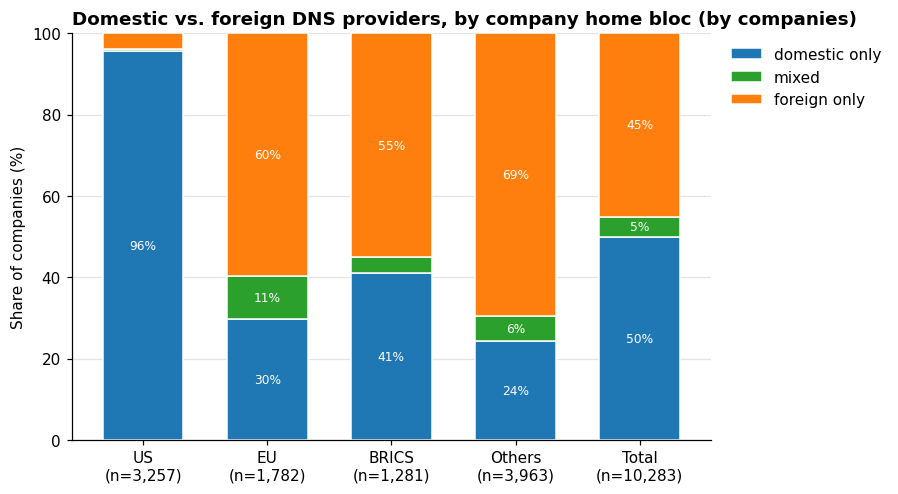

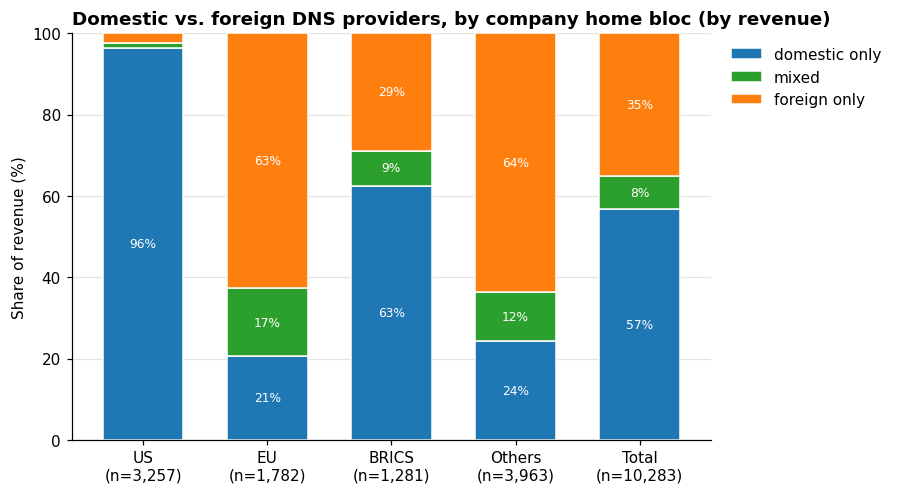

In [29]:
# GRÁFICO 1: barras empilhadas (cada barra = um bloco, soma 100%), um gráfico por ponderação
cores_tipos = {"domestic only": PALETA[0], "mixed": PALETA[2], "foreign only": PALETA[1]}

for pond, unidade in PONDERACOES.items():
    tab = tab_tipos[pond]

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    tab.plot.bar(ax=ax, stacked=True, width=0.65, edgecolor="white",
                 color=[cores_tipos[t] for t in tab.columns])

    # escrevo o % dentro de cada pedaço (só nos pedaços com 4% ou mais)
    for pedacos in ax.containers:
        ax.bar_label(pedacos, labels=[f"{v:.0f}%" if v >= 4 else "" for v in pedacos.datavalues],
                     label_type="center", fontsize=8, color="white")

    ax.set_title(f"Domestic vs. foreign DNS providers, by company home bloc (by {unidade})")
    ax.grid(axis="x", visible=False)   # o pandas liga a grade vertical; deixo só a horizontal
    ax.set_xlabel("")
    ax.set_ylabel(f"Share of {unidade} (%)")
    ax.set_xticklabels(rotulos_com_n(n_empresas), rotation=0)
    ax.set_ylim(0, 100)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")

    salvar_figura(fig, "fig_dep_tipos_blocos", pond)
    plt.show()

## 4. Para onde vai a dependência? (bloco da empresa → bloco do provedor)

Somo o `valor` das linhas empresa–provedor por bloco da empresa e bloco do provedor, e
transformo em % de cada bloco de origem. Exemplo de leitura: "das empresas da UE, X% do DNS
está em provedores dos EUA".

> No método `uso`, a % é sobre o total de relações empresa–provedor do bloco.

In [30]:
# % do valor de cada bloco de empresas que vai para cada bloco de provedores, uma tabela por ponderação
tab_destino = {}
for pond, unidade in PONDERACOES.items():
    tab = (base.pivot_table(index="bloco_empresa", columns="bloco_provedor", values=f"valor_{pond}", aggfunc="sum")
               .reindex(index=ORDEM_BLOCOS, columns=ORDEM_BLOCOS[:-1])
               .fillna(0))
    tab_destino[pond] = 100 * tab.div(tab.sum(axis=1), axis=0)   # % de cada linha

    print(f"Share of {unidade} (%)")
    display(tab_destino[pond].round(1))
    salvar_tabela(tab_destino[pond], "dep_destino_blocos", pond)

Share of companies (%)


bloco_provedor,US,EU,BRICS,Others
bloco_empresa,,,,
US,96.1,1.8,0.0,2.2
EU,47.3,50.8,0.0,1.9
BRICS,51.9,2.8,43.3,2.0
Others,65.1,4.2,1.5,29.2
Total,70.2,11.3,6.0,12.5


Share of revenue (%)


bloco_provedor,US,EU,BRICS,Others
bloco_empresa,,,,
US,97.3,1.5,0.1,1.1
EU,59.9,38.9,0.1,1.1
BRICS,28.4,0.7,67.9,3.1
Others,61.9,3.1,2.1,32.9
Total,69.4,7.8,11.5,11.3


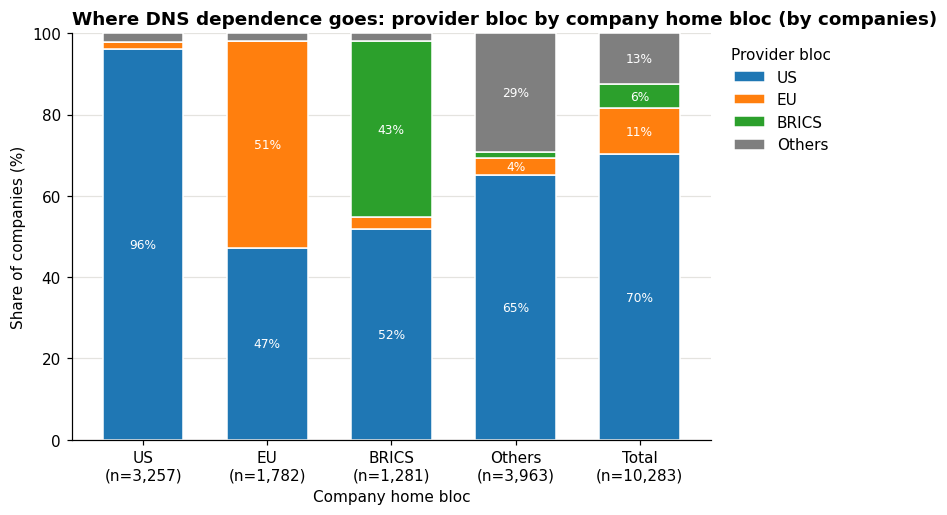

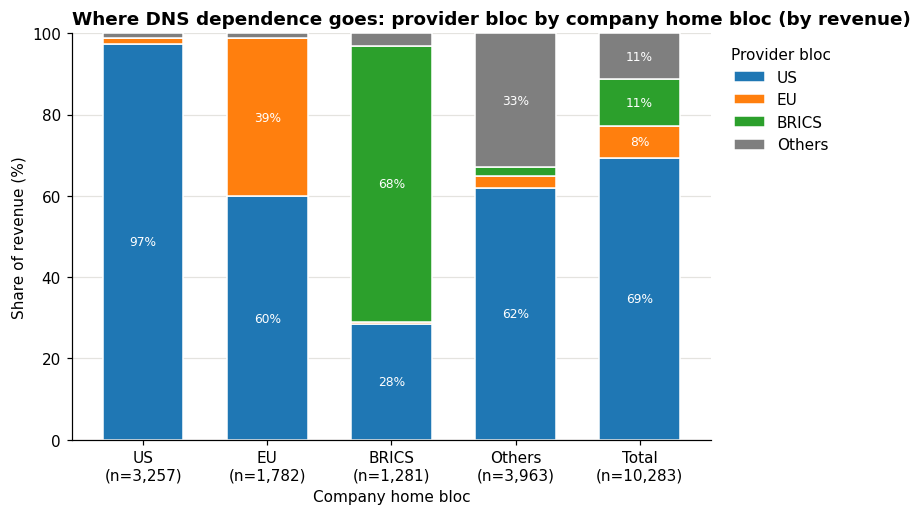

In [31]:
# GRÁFICO 2: barras empilhadas, com a cor indicando o bloco do PROVEDOR, um gráfico por ponderação
for pond, unidade in PONDERACOES.items():
    tab = tab_destino[pond]

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    tab.plot.bar(ax=ax, stacked=True, width=0.65, edgecolor="white",
                 color=[CORES_BLOCOS[b] for b in tab.columns])

    for pedacos in ax.containers:
        ax.bar_label(pedacos, labels=[f"{v:.0f}%" if v >= 4 else "" for v in pedacos.datavalues],
                     label_type="center", fontsize=8, color="white")

    ax.set_title(f"Where DNS dependence goes: provider bloc by company home bloc (by {unidade})")
    ax.grid(axis="x", visible=False)   # o pandas liga a grade vertical; deixo só a horizontal
    ax.set_xlabel("Company home bloc")
    ax.set_ylabel(f"Share of {unidade} (%)")
    ax.set_xticklabels(rotulos_com_n(n_empresas), rotation=0)
    ax.set_ylim(0, 100)
    ax.legend(title="Provider bloc", bbox_to_anchor=(1.01, 1), loc="upper left")

    salvar_figura(fig, "fig_dep_destino_blocos", pond)
    plt.show()

## 5. Dependência de provedores dos EUA

Como os maiores provedores são americanos, vale olhar diretamente: que % das empresas de
cada bloco **usa pelo menos um** provedor dos EUA, e que % **usa apenas** provedores dos EUA?

> Para o bloco US isso é dependência doméstica. Ele aparece no gráfico só como referência.

In [32]:
base["provedor_eua"] = base["pais_provedor"] == "US"

# uma linha por empresa: usa algum provedor dos EUA? usa só provedores dos EUA?
eua = base.groupby(["bloco_empresa", "rank"], as_index=False).agg(
    usa_algum_eua=("provedor_eua", "any"),
    usa_so_eua=("provedor_eua", "all"),
    peso_empresas=("peso_empresas", "first"),
    peso_receita=("peso_receita", "first"),
)

# % das empresas (ou da receita) de cada bloco: soma do peso das empresas que atendem ao critério / total
tab_eua = {}
for pond, unidade in PONDERACOES.items():
    peso = f"peso_{pond}"
    tab = pd.DataFrame({
        "At least one US provider": eua[eua["usa_algum_eua"]].groupby("bloco_empresa")[peso].sum(),
        "Only US providers": eua[eua["usa_so_eua"]].groupby("bloco_empresa")[peso].sum(),
    })
    tab_eua[pond] = (100 * tab.div(eua.groupby("bloco_empresa")[peso].sum(), axis=0)).reindex(ORDEM_BLOCOS).fillna(0)

    print(f"Share of {unidade} (%)")
    display(tab_eua[pond].round(1))
    salvar_tabela(tab_eua[pond], "dep_eua_blocos", pond)

Share of companies (%)


,At least one US provider,Only US providers
bloco_empresa,,
US,96.3,95.7
EU,53.4,42.5
BRICS,54.3,50.0
Others,68.5,62.6
Total,72.9,68.0


Share of revenue (%)


,At least one US provider,Only US providers
bloco_empresa,,
US,97.7,96.5
EU,71.0,52.6
BRICS,33.7,25.1
Others,69.3,56.4
Total,74.5,65.8


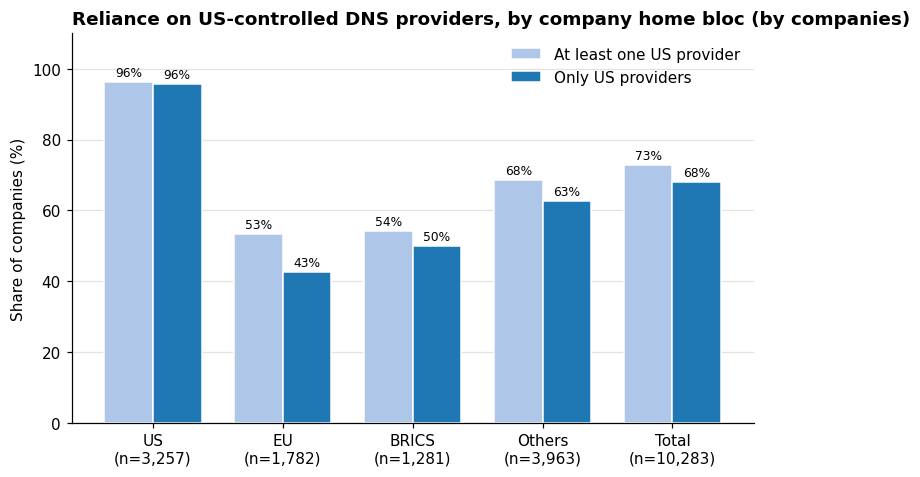

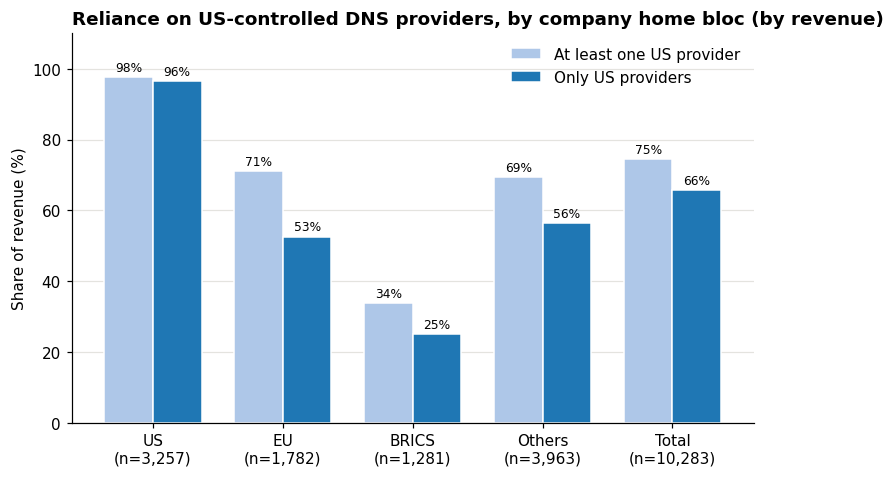

In [33]:
# GRÁFICO 3: barras lado a lado (para cada bloco: "pelo menos um" e "apenas"), um gráfico por ponderação
for pond, unidade in PONDERACOES.items():
    fig, ax = plt.subplots(figsize=(8, 4.6))
    tab_eua[pond].plot.bar(ax=ax, width=0.75, edgecolor="white",
                           color=[plt.get_cmap("tab20").colors[1], PALETA[0]])

    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.0f%%", padding=2, fontsize=8)

    ax.set_title(f"Reliance on US-controlled DNS providers, by company home bloc (by {unidade})")
    ax.grid(axis="x", visible=False)   # o pandas liga a grade vertical; deixo só a horizontal
    ax.set_xlabel("")
    ax.set_ylabel(f"Share of {unidade} (%)")
    ax.set_xticklabels(rotulos_com_n(n_empresas), rotation=0)
    ax.set_ylim(0, 110)
    ax.legend(loc="upper right")

    salvar_figura(fig, "fig_dep_eua_blocos", pond)
    plt.show()

## 6. Notas para a leitura

- O país do provedor é o país do **grupo controlador** do ASN (jurisdição), e não a localização
  dos servidores. Um provedor americano com servidores no Brasil conta como estrangeiro para
  uma empresa brasileira.
- Empresas sediadas em paraísos fiscais (Bermudas, Ilhas Cayman etc.) tendem a aparecer como
  *foreign only*, porque a sede formal não coincide com o país onde operam.
- Todo gráfico sai nas duas ponderações (empresas e receita). Para gerar as versões de outro
  método, basta mudar `METODO` na primeira célula de código e rodar tudo de novo. Os arquivos
  saem com o método e a ponderação no nome (ex.: `_fracionado_receita`).